# HR Analytics: Job Change Analysis

**Goal:** This project explores how candidate characteristics relate to job-change intent.

**Dataset:** HR Analytics: Job Change of Data Scientists, from [Kaggle](https://www.kaggle.com/datasets/arashnic/hr-analytics-job-change-of-data-scientists). The dataset contains 19,158 rows and 14 columns.

**Tools:** Python, Pandas, NumPy, Seaborn, Matplotlib, and Jupyter Notebook.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

df = pd.read_csv("aug_train.csv")
df

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,never,83,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,never,52,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19153,7386,city_173,0.878,Male,No relevent experience,no_enrollment,Graduate,Humanities,14,NaN,NaN,1,42,1.0
19154,31398,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,14,NaN,NaN,4,52,1.0
19155,24576,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,50-99,Pvt Ltd,4,44,0.0
19156,5756,city_65,0.802,Male,Has relevent experience,no_enrollment,High School,NaN,<1,500-999,Pvt Ltd,2,97,0.0


## 1. Data Inspection

**To do:** shape, info, describe, missing values, duplicates, value counts for text columns.

In [ ]:
print("shape:",df.shape)

shape: (19158, 14)


In [3]:
print("missing value:", df.info())

<class 'pandas.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   enrollee_id             19158 non-null  int64  
 1   city                    19158 non-null  str    
 2   city_development_index  19158 non-null  float64
 3   gender                  14650 non-null  str    
 4   relevent_experience     19158 non-null  str    
 5   enrolled_university     18772 non-null  str    
 6   education_level         18698 non-null  str    
 7   major_discipline        16345 non-null  str    
 8   experience              19093 non-null  str    
 9   company_size            13220 non-null  str    
 10  company_type            13018 non-null  str    
 11  last_new_job            18735 non-null  str    
 12  training_hours          19158 non-null  int64  
 13  target                  19158 non-null  float64
dtypes: float64(2), int64(2), str(10)
memory usage: 2.

In [4]:
df.describe()

,enrollee_id,city_development_index,training_hours,target
count,19158.000000,19158.000000,19158.000000,19158.000000
mean,16875.358179,0.828848,65.366896,0.249348
std,9616.292592,0.123362,60.058462,0.432647
min,1.000000,0.448000,1.000000,0.000000
25%,8554.250000,0.740000,23.000000,0.000000
50%,16982.500000,0.903000,47.000000,0.000000
75%,25169.750000,0.920000,88.000000,0.000000
max,33380.000000,0.949000,336.000000,1.000000


In [5]:
(df.isnull().sum() / len(df) * 100).round(2)

enrollee_id                0.00
city                       0.00
city_development_index     0.00
gender                    23.53
relevent_experience        0.00
enrolled_university        2.01
education_level            2.40
major_discipline          14.68
experience                 0.34
company_size              30.99
company_type              32.05
last_new_job               2.21
training_hours             0.00
target                     0.00
dtype: float64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df["gender"].value_counts(dropna=False)

gender
Male      13221
NaN        4508
Female     1238
Other       191
Name: count, dtype: int64

In [8]:
df["company_type"].value_counts(dropna=False)

company_type
Pvt Ltd                9817
NaN                    6140
Funded Startup         1001
Public Sector           955
Early Stage Startup     603
NGO                     521
Other                   121
Name: count, dtype: int64

In [9]:
df["company_size"].value_counts(dropna=False)

company_size
NaN          5938
50-99        3083
100-500      2571
10000+       2019
10/49        1471
1000-4999    1328
<10          1308
500-999       877
5000-9999     563
Name: count, dtype: int64

In [10]:
df["education_level"].value_counts(dropna=False)

education_level
Graduate          11598
Masters            4361
High School        2017
NaN                 460
Phd                 414
Primary School      308
Name: count, dtype: int64

In [11]:
df["experience"].value_counts(dropna=False)

experience
>20    3286
5      1430
4      1403
3      1354
6      1216
2      1127
7      1028
10      985
9       980
8       802
15      686
11      664
14      586
1       549
<1      522
16      508
12      494
13      399
17      342
19      304
18      280
20      148
NaN      65
Name: count, dtype: int64

In [12]:
df.dtypes

enrollee_id                 int64
city                          str
city_development_index    float64
gender                        str
relevent_experience           str
enrolled_university           str
education_level               str
major_discipline              str
experience                    str
company_size                  str
company_type                  str
last_new_job                  str
training_hours              int64
target                    float64
dtype: object

In [13]:
df["target"].value_counts(dropna=False)
df["target"].value_counts(normalize=True, dropna=False) * 100

target
0.0    75.065247
1.0    24.934753
Name: proportion, dtype: float64

### What I found

- **Dataset size:** 19,158 rows and 14 columns.
- **Missing values:**
  - `gender`: 4,508 (23.53%)
  - `enrolled_university`: 386 (2.01%)
  - `education_level`: 460 (2.40%)
  - `major_discipline`: 2,813 (14.68%)
  - `experience`: 65 (0.34%)
  - `company_size`: 5,938 (30.99%)
  - `company_type`: 6,140 (32.05%)
  - `last_new_job`: 423 (2.21%)
- **Duplicates:** No full-row duplicates were found.
- **Data type issues:** `experience` and `last_new_job` contain text categories such as `<1`, `>20`, `never`, and `>4`. I mapped these categories to numeric codes for analysis. These codes are approximations, not exact measurements.
- **Target distribution:** 14,381 candidates (75.07%) have `target = 0`, and 4,777 (24.93%) have `target = 1`.
- **Next step:** Handle missing values, standardize inconsistent category labels, and document any numeric mappings.

## 2. Data Cleaning &  Cleaning decisions:


**To do:** handle missing values, fix text columns that should be numeric, fix inconsistent formats, check duplicates.

For every decision, write **what you did** and **why**.

In [ ]:
df_clean = df.copy()

**What:**  copy the data

**Why:** avoiding errors

**Result:** no mistake the data 

In [ ]:
df_clean["company_type"] = df_clean["company_type"].fillna("Unknown")

**What:** Filled missing `company_type` values with "Unknown".

**Why:** 32.05% of the column is missing, so dropping those rows would remove too much data.

**Result:** No missing values left in this column.

In [16]:
df_clean["major_discipline"] = df_clean["major_discipline"].fillna("Unknown")

**What:** Filled missing `major_discipline` values with "Unknown".

**Why:** 14.68% of the column is missing, so dropping those rows would remove too much data.

**Result:** No missing values left in this column.

In [17]:
df_clean["education_level"] = df_clean["education_level"].fillna("Unknown")

**What:** Filled missing `education_level` values with "Unknown".

**Why:** 2.40% of the column is missing, so dropping those rows would remove too much data.

**Result:** No missing values left in this column.

In [18]:
df_clean["enrolled_university"] = df_clean["enrolled_university"].fillna("Unknown")

**What:** Filled missing `enrolled_university` values with "Unknown".

**Why:** 2.01% of the column is missing, so dropping those rows would remove too much data.

**Result:** No missing values left in this column.

In [19]:
df_clean["gender"] = df_clean["gender"].fillna("Unknown")

**What:** Filled missing `gender` values with "Unknown".

**Why:** 23.53% of the column is missing, so dropping those rows would remove too much data.

**Result:** No missing values left in this column.

In [20]:
df_clean["company_size"] = df_clean["company_size"].fillna("Unknown")

**What:** Filled missing `company_size` values with "Unknown".

**Why:** 30.99% of the column is missing, so dropping those rows would remove too much data.

**Result:** No missing values left in this column.

In [21]:
df["experience"].unique()

<StringArray>
['>20',  '15',   '5',  '<1',  '11',  '13',   '7',  '17',   '2',  '16',   '1',
   '4',  '10',  '14',  '18',  '19',  '12',   '3',   '6',   '9',   '8',  '20',
   nan]
Length: 23, dtype: str

In [22]:
df_clean["experience"] = df_clean["experience"].replace({">20": "21", "<1": "0"})
df_clean["experience"] = pd.to_numeric(df_clean["experience"])

**What:** Replaced `<1` with 0 and `>20` with 21 in `experience`.

**Why:** These numeric codes represent the lower-end values of the categories and allow numeric analysis. They are approximations, not exact years of experience.

**Result:** The category labels were converted to numbers. The 65 missing values remained and were filled with the median in the next step.

In [23]:
# Support the Solution
print("dtype:",df_clean["experience"].dtype)       
print("min:",df_clean["experience"].min())      
print("max:",df_clean["experience"].max())     
print("sum:",df_clean["experience"].isnull().sum())   

dtype: float64
min: 0.0
max: 21.0
sum: 65


In [24]:
median_exp = df_clean["experience"].median()
df_clean["experience"] = df_clean["experience"].fillna(median_exp)
df_clean["experience"].isnull().sum()

np.int64(0)

**What:** Filled 65 missing `experience` values with the median (9.0).

**Why:** Only 0.34% of rows were missing, and the median is robust to extreme values, so it keeps all rows without distorting the distribution.

**Result:** No missing values in `experience`.

In [25]:
df_clean["last_new_job"]=df_clean["last_new_job"].replace({"never":"0" , ">4" : "5"})

In [26]:
print("dtype:",df_clean["last_new_job"].dtype)       
print("min:",df_clean["last_new_job"].min())      
print("max:",df_clean["last_new_job"].max())     
print("sum:",df_clean["last_new_job"].isnull().sum()) 

dtype: str
min: 0
max: 5
sum: 423


**What:** Replaced `never` with 0 and `>4` with 5.

**Why:** `never` represents no previous job change, and `>4` means more than four years. The values 0 and 5 are numeric codes used for analysis, not exact measurements.

**Result:** The text categories were converted to numeric values.

In [27]:
df_clean["company_size"]=df_clean["company_size"].replace({"10/49":"10-49"})

**What:**replace "10/49"to 10-49.

**Why:** for equal the data in the columns.

**Result:** No missing values left in this column.

In [28]:
df_clean["target"]=df_clean["target"].astype("int64")
df_clean["target"].dtype

dtype('int64')

**What:**support the cols as 0 , 1 only .

**Why:** for the visualization.

**Result:** No missing values left in this column.

In [29]:
df_clean["enrollee_id"].duplicated().sum()

np.int64(0)

**What:** show the duplicated in cols.

**Why:** no error and  duplicated.

**Result:** No duplicated.

In [30]:
df_clean = df_clean.rename(columns={"relevent_experience": "relevant_experience"})


**What:** Renamed `relevent_experience` to `relevant_experience`.

**Why:** The original name had a spelling mistake.

In [31]:
df_clean.columns

Index(['enrollee_id', 'city', 'city_development_index', 'gender',
       'relevant_experience', 'enrolled_university', 'education_level',
       'major_discipline', 'experience', 'company_size', 'company_type',
       'last_new_job', 'training_hours', 'target'],
      dtype='str')

In [32]:
df_clean.describe()

,enrollee_id,city_development_index,experience,training_hours,target
count,19158.000000,19158.000000,19158.000000,19158.000000,19158.000000
mean,16875.358179,0.828848,10.096409,65.366896,0.249348
std,9616.292592,0.123362,6.765820,60.058462,0.432647
min,1.000000,0.448000,0.000000,1.000000,0.000000
25%,8554.250000,0.740000,4.000000,23.000000,0.000000
50%,16982.500000,0.903000,9.000000,47.000000,0.000000
75%,25169.750000,0.920000,16.000000,88.000000,0.000000
max,33380.000000,0.949000,21.000000,336.000000,1.000000


**What:** find the describe

**Why:** review the data from outliers

**Result:** found outlier in `training_hours`.

In [33]:
q1 = df_clean["training_hours"].quantile(0.25)
q3 = df_clean["training_hours"].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

**What:** Detected 984 outliers (5.1%) in `training_hours` using the IQR method (upper bound 185.5).

**Why I kept them:** These are plausible values (long training hours), not data errors, and the distribution is naturally 
right-skewed. Their job-change rate (21.3%) is close to the rest (25.1%).

**Result:** No change to the data.

================

### Review the cleaning data

In [34]:
df_clean.isnull().sum()

enrollee_id                 0
city                        0
city_development_index      0
gender                      0
relevant_experience         0
enrolled_university         0
education_level             0
major_discipline            0
experience                  0
company_size                0
company_type                0
last_new_job              423
training_hours              0
target                      0
dtype: int64

In [35]:
df_clean["last_new_job"] = pd.to_numeric(df_clean["last_new_job"])

In [36]:
median_exp1 = df_clean["last_new_job"].median()
df_clean["last_new_job"] = df_clean["last_new_job"].fillna(median_exp1)
df_clean["last_new_job"].isnull().sum()

np.int64(0)

In [37]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   enrollee_id             19158 non-null  int64  
 1   city                    19158 non-null  str    
 2   city_development_index  19158 non-null  float64
 3   gender                  19158 non-null  str    
 4   relevant_experience     19158 non-null  str    
 5   enrolled_university     19158 non-null  str    
 6   education_level         19158 non-null  str    
 7   major_discipline        19158 non-null  str    
 8   experience              19158 non-null  float64
 9   company_size            19158 non-null  str    
 10  company_type            19158 non-null  str    
 11  last_new_job            19158 non-null  float64
 12  training_hours          19158 non-null  int64  
 13  target                  19158 non-null  int64  
dtypes: float64(3), int64(3), str(8)
memory usage: 2.0

In [38]:
df_clean.isnull().sum().sum()

np.int64(0)

==========================================
#### THE DATA IS CLEANING NOW
==========================================

## save the data

In [39]:
df_clean.to_csv("HR_clean.csv", index=False)

## 3. Analysis

**Questions to answer** (one cell per question, with a short comment under each result):


1. What percentage of people are looking for a job change?

In [40]:
percentage=df_clean["target"].agg(["mean"])

2. How does relevant experience relate to the target?

In [41]:
relate_re_and_t=df_clean.groupby("relevant_experience")["target"].agg(["mean", "count"])
relate_re_and_t["mean"] *= 100
relate_re_and_t

,mean,count
relevant_experience,,
Has relevent experience,21.468968,13792
No relevent experience,33.842713,5366


3. How does enrolled university relate to the target?


In [42]:
relate_eu_and_t=df_clean.groupby("enrolled_university")["target"].agg(["mean","count"])
relate_eu_and_t["mean"] *=100
relate_eu_and_t

,mean,count
enrolled_university,,
Full time course,38.088901,3757
Part time course,25.208681,1198
Unknown,31.865285,386
no_enrollment,21.140624,13817


4. How do city development index and training hours correlate with the target?


In [43]:
th_corr=df_clean[["city_development_index", "training_hours", "target"]].corr()
th_corr

,city_development_index,training_hours,target
city_development_index,1.000000,0.001920,-0.341665
training_hours,0.001920,1.000000,-0.021577
target,-0.341665,-0.021577,1.000000


City development index has a moderate negative correlation with job-change intent (-0.34), while training hours show almost no relationship (-0.02).

5. How does experience group relate to the target?

In [44]:
experience=df_clean.groupby("experience")["target"].agg(["mean", "count"])
experience

,mean,count
experience,,
0.0,0.454023,522
1.0,0.424408,549
2.0,0.331854,1127
3.0,0.353028,1354
4.0,0.325731,1403
5.0,0.288112,1430
6.0,0.282072,1216
7.0,0.294747,1028
8.0,0.243142,802


## 4. Visualizations

**Rule:** every chart needs a title, labeled axes, and a sentence under it saying what it shows.

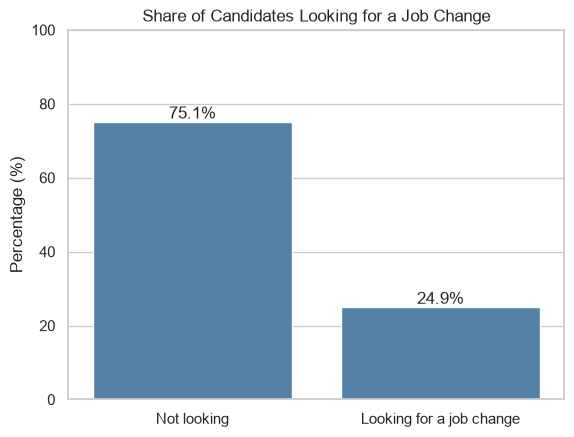

In [45]:
p = df_clean["target"].mean() * 100                       # 24.9
data = pd.Series({"Not looking": 100 - p,                  # 75.1
                "Looking for a job change": p})          # 24.9

ax = sns.barplot(x=data.index, y=data.values, color="steelblue")
ax.bar_label(ax.containers[0], fmt="%.1f%%")
ax.set(title="Share of Candidates Looking for a Job Change",
    xlabel="", ylabel="Percentage (%)", ylim=(0, 100))
plt.savefig("images/target.png", dpi=100)
plt.show()

### explanation


**Based on the target variable, 24.9% of people are looking for a new job, while 75.1% are not.**

========

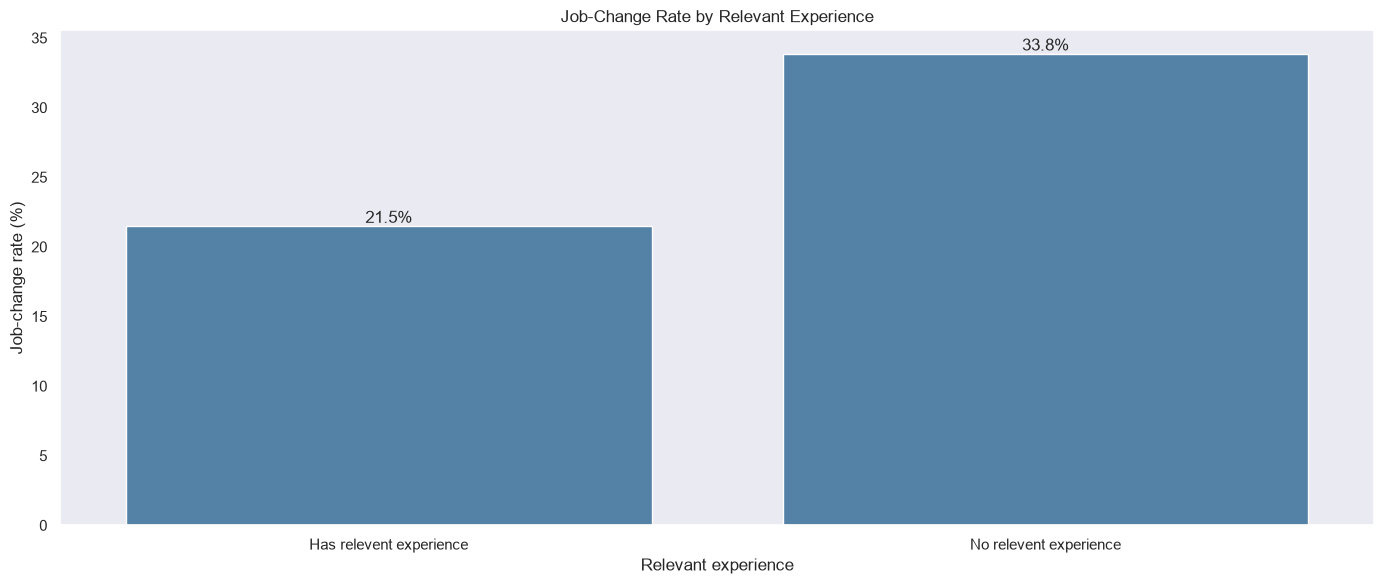

In [46]:
sns.set_theme(style="dark")
fig, ax = plt.subplots(figsize=(14, 6))
ax = sns.barplot(
    data=relate_re_and_t,
    x="relevant_experience",
    y="mean",
    color="steelblue"
)

ax.bar_label(ax.containers[0], fmt="%.1f%%")
ax.set_title("Job-Change Rate by Relevant Experience")
ax.set_xlabel("Relevant experience")
ax.set_ylabel("Job-change rate (%)")
plt.savefig("images/Relevant experience.png", dpi=100)
plt.tight_layout()
plt.show()


### explanation

**People with relevant experience are less likely to look for a new job (21.5%) than those without relevant experience (33.8%).**

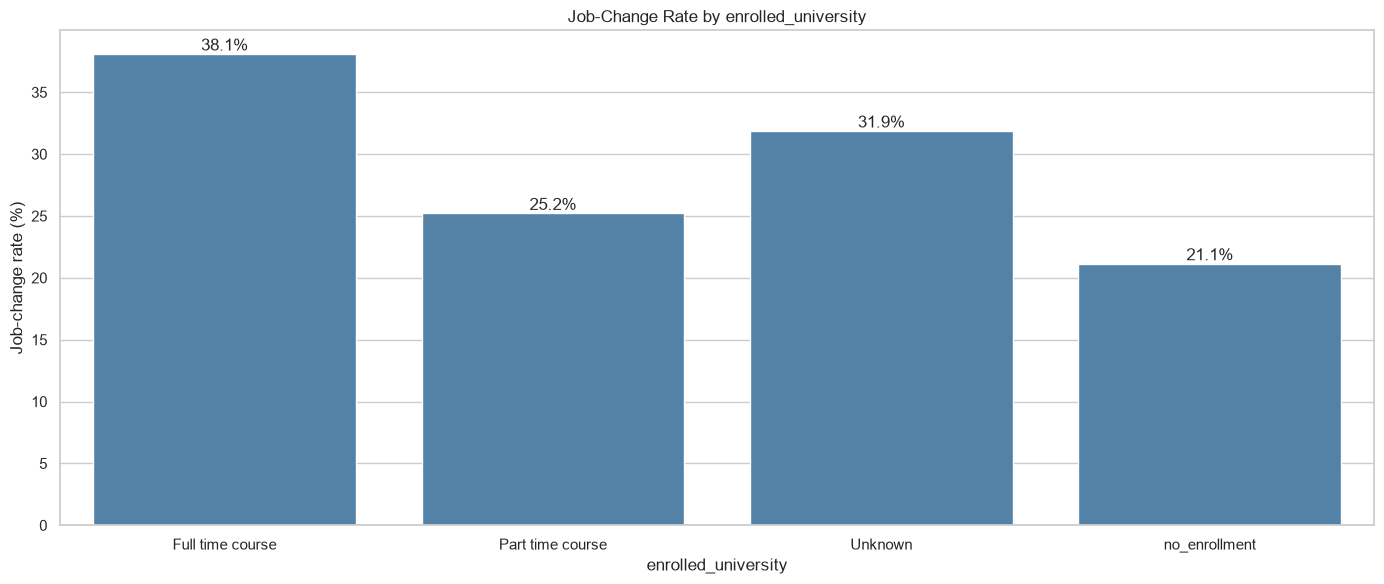

In [47]:
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(14, 6))
ax = sns.barplot(
    data=relate_eu_and_t,
    x="enrolled_university",
    y="mean",
    color="steelblue"
)

ax.bar_label(ax.containers[0], fmt="%.1f%%")
ax.set_title("Job-Change Rate by enrolled_university")
ax.set_xlabel("enrolled_university")
ax.set_ylabel("Job-change rate (%)")
plt.savefig("images/enrolled_university.png", dpi=100)
plt.tight_layout()
plt.show()


### explanation

**People enrolled in a full-time course have the highest job-change rate (38.1%), compared with 25.2% for part-time students and 21.1% for those with no university enrollment.**

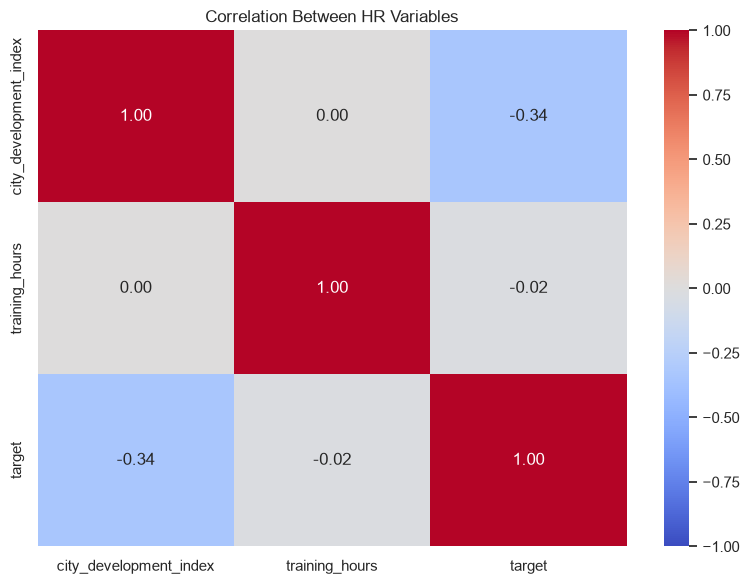

In [48]:
fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    th_corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f",
    ax=ax
)

ax.set_title("Correlation Between HR Variables")
plt.savefig("images/Correlation Between HR Variables.png", dpi=100)
plt.tight_layout()
plt.show()

### explanation

**The city development index has a moderate negative correlation with job-change intent (r = −0.34), while training hours show almost no correlation (r = −0.02)**

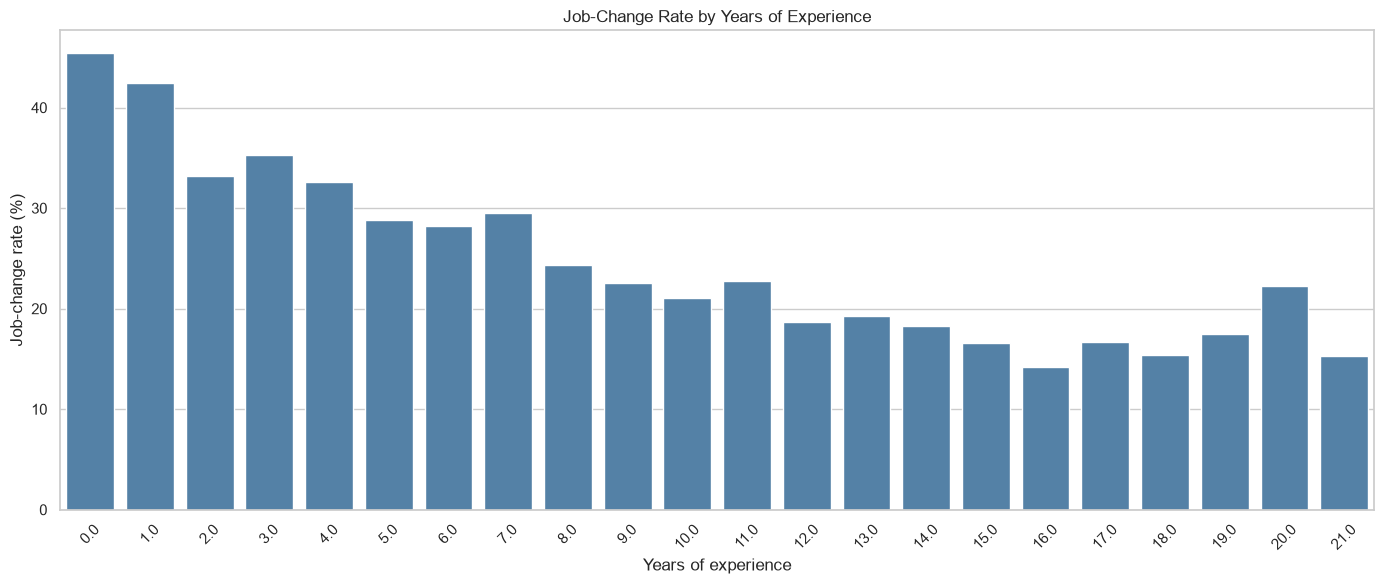

In [49]:
experience_plot = experience.reset_index().copy()
experience_plot["mean"] *= 100

fig, ax = plt.subplots(figsize=(14, 6))

sns.barplot(
    data=experience_plot,
    x="experience",
    y="mean",
    color="steelblue",
    ax=ax
)

ax.set(
    title="Job-Change Rate by Years of Experience",
    xlabel="Years of experience",
    ylabel="Job-change rate (%)"
)

plt.xticks(rotation=45)
plt.savefig("images/Job-Change Rate by Years of Experience.png", dpi=100)

plt.tight_layout()
plt.show()


### explanation

**The job-change rate generally decreases as years of experience increase, although there are some fluctuations**